# Graph 5: Trend over time — growth between 2011 and 2012
Run `01_data_processing.ipynb` first.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
data = pd.read_pickle("processed/data.pkl")

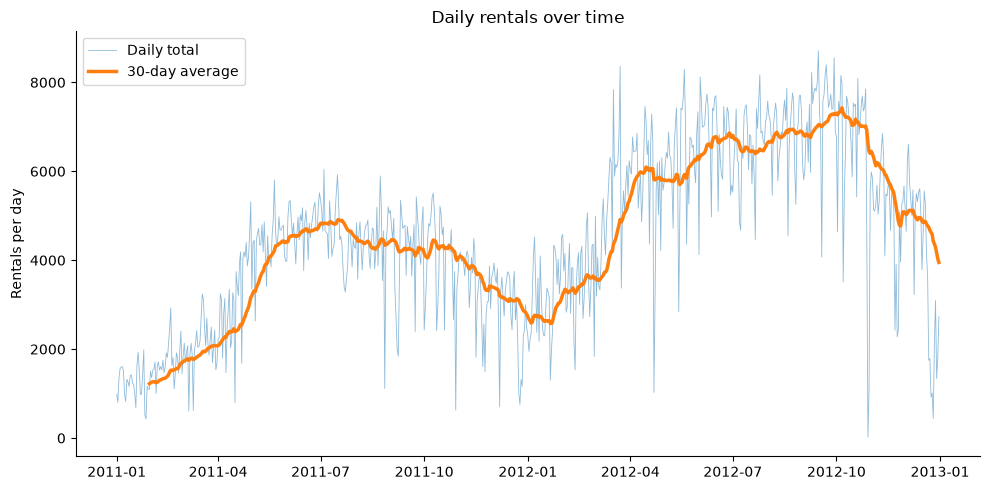

datetime
2011    143.794448
2012    234.666361
Name: avg rentals/hour, dtype: float64


In [3]:
daily = data.set_index("datetime")["cnt"].resample("D").sum()
plt.plot(daily.index, daily.values, lw=0.6, alpha=0.5, label="Daily total")
plt.plot(daily.rolling(30).mean(), lw=2.5, label="30-day average")
plt.title("Daily rentals over time"); plt.ylabel("Rentals per day"); plt.legend()
plt.tight_layout(); plt.savefig("figures/05_trend.png", dpi=150); plt.show()

print(data.groupby(data["datetime"].dt.year)["cnt"].mean().rename("avg rentals/hour"))